# Демонстрации к лекции 9: алгоритмы для равенств

Ноутбук — для самостоятельной проверки после пары. Всё, что на лекции было формулой или картинкой, здесь считается кодом. У каждой ячейки с кодом две подписи: **«Что делает ячейка»** перед ней и **«Что видим»** после неё. Числа конспекта печатаются рядом с ожидаемыми.

- **(0)** числа введения: бросок без воздуха и стартовые стержни цепи;
- **(a)** метод Ньютона–Лагранжа (§2): шаг руками на окружности, итерации, цепь против IPOPT;
- **(b)** матрица ККТ и шаг по частям (§3–§4): где $K$ вырождена, три способа найти один шаг;
- **(c)** обобщённый Гаусс–Ньютон (§5): множитель ошибки равен $\lambda^\ast$;
- **(e)** подробности: старт из арки, выбор $\lambda^{(0)}$, лог IPOPT рядом с нашей невязкой.

Конспект: [`lecture09.md`](lecture09.md). Запуск: `uv run --group casadi jupyter lab` в корне репозитория. В Colab первая ячейка ставит CasADi сама.

In [1]:
%matplotlib inline

import importlib.util, subprocess, sys
if importlib.util.find_spec("casadi") is None:          # Colab: поставить CasADi один раз
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "casadi"], check=True)

import casadi as ca
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import null_space

BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7"
GRAY, INK = "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})


# ---------------------------------------------------------------- методы (те же, что в demo09 / l9helpers.py)
def newton_lagrange(kkt, x0, lam0, tol=1e-10, maxit=50):
    """Метод Ньютона–Лагранжа для min f при g(x) = 0, знак L = f - lam^T g.
    kkt(x, lam) -> (grad f, J, H, g), где H — гессиан L по x.
    Шаг: [[H, -J^T], [J, 0]] (p, dlam) = -(grad_x L, g).
    Возвращает список (x_k, lam_k, |F_k|) по итерациям, включая старт."""
    x, lam = np.array(x0, float), np.array(lam0, float)
    n, m = len(x), len(lam)
    hist = []
    for k in range(maxit + 1):
        gf, J, H, g = kkt(x, lam)
        F = np.concatenate([gf - J.T @ lam, g])                                     # невязка системы
        hist.append((x.copy(), lam.copy(), np.linalg.norm(F)))
        if hist[-1][2] <= tol or k == maxit:
            break
        K = np.block([[H, -J.T], [J, np.zeros((m, m))]])                           # матрица ККТ
        s = np.linalg.solve(K, -F)
        x, lam = x + s[:n], lam + s[n:]
    return hist


def casadi_kkt(x, f, g):
    """Производные для newton_lagrange от CasADi (алгоритмическое дифференцирование, лекция 7).
    x, f, g — символьные выражения CasADi. Возвращает kkt(x, lam) -> (grad f, J, H, g) в numpy, H — гессиан L = f - lam^T g."""
    lam = ca.SX.sym("lam", g.shape[0])
    fun = ca.Function("kkt", [x, lam], [ca.gradient(f, x), ca.jacobian(g, x), ca.hessian(f - ca.dot(lam, g), x)[0], g])

    def kkt(xv, lv):
        gf, J, H, gv = fun(xv, lv)
        return np.array(gf.full()).ravel(), np.array(J.full()), np.array(H.full()), np.array(gv.full()).ravel()
    return kkt


# ---------------------------------------------------------------- окружность (лекция 8, задача 1)
A_CIRCLE = np.array([2.0, 1.0])


def circle_kkt(a):
    """f = 1/2 |x - a|^2, g = 1/2 (|x|^2 - 1): grad f = x - a, J = x^T, H = (1 - lam) I."""
    def kkt(x, lam):
        return x - a, x[None, :], (1 - lam[0]) * np.eye(2), np.array([0.5 * (x @ x - 1)])
    return kkt


def ggn_circle(a, x0, iters):
    """Обобщённый Гаусс–Ньютон на окружности: R = x - a, J_R = I, в матрице ККТ B = I вместо H.
    Шаг — проекция a на прямую g(x_k) + J p = 0. Возвращает точки x_0..x_iters."""
    x = np.array(x0, float); xs = [x.copy()]
    for _ in range(iters):
        J = x[None, :]
        K = np.block([[np.eye(2), -J.T], [J, np.zeros((1, 1))]])
        s = np.linalg.solve(K, -np.concatenate([x - a, [0.5 * (x @ x - 1)]]))      # lam не входит: правая часть без -J^T lam
        x = x + s[:2]; xs.append(x.copy())
    return np.array(xs)


def angle_err(xs, a):
    """Угол между точками и лучом к a, рад (знак — по какую сторону)."""
    return np.arctan2(xs[:, 1], xs[:, 0]) - np.arctan2(a[1], a[0])


# ---------------------------------------------------------------- цепь на стержнях (лекция 8, задача 2)
def rod_chain(N=3, L_total=5.0, m=1.0, g_acc=9.81):
    """N грузов массы m между (-2, 1) и (2, 1), N + 1 стержней длины L_total / (N + 1), f = w sum z.
    Переменные v = (y_1..y_N, z_1..z_N). Возвращает словарь с символьными v, f, g, функцией kkt, весом w, длиной ell."""
    w = m * g_acc; ell = L_total / (N + 1)
    v = ca.SX.sym("v", 2 * N)
    y = ca.vertcat(-2.0, v[:N], 2.0); z = ca.vertcat(1.0, v[N:], 1.0)              # опоры по краям
    f = w * ca.sum1(z[1:-1])                                                        # энергия: вес на высоту
    g = ca.vertcat(*[(y[j + 1] - y[j]) ** 2 + (z[j + 1] - z[j]) ** 2 - ell ** 2 for j in range(N + 1)])
    t = np.linspace(-2, 2, N + 2)[1:-1]
    return dict(v=v, f=f, g=g, kkt=casadi_kkt(v, f, g), w=w, ell=ell, N=N, v0=np.concatenate([t, np.zeros(N)]))


def lam_ls(kkt, x, m):
    """Стартовые множители по МНК: grad f ≈ J^T lam."""
    gf, J, _, _ = kkt(x, np.zeros(m))
    return np.linalg.lstsq(J.T, gf, rcond=None)[0]


def solve_rod_chain(ch, v0=None, tol=1e-10):
    """IPOPT для цепи. Возвращает (v*, lam* в нашем знаке, stats)."""
    solver = ca.nlpsol("s", "ipopt", {"x": ch["v"], "f": ch["f"], "g": ch["g"]},
                       {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes", "ipopt.tol": tol})
    sol = solver(x0=ch["v0"] if v0 is None else v0, lbg=0, ubg=0)
    return np.array(sol["x"]).ravel(), -np.array(sol["lam_g"]).ravel(), solver.stats()


def chain_xy(ch, v):
    N = ch["N"]
    return np.concatenate([[-2.0], v[:N], [2.0]]), np.concatenate([[1.0], v[N:], [1.0]])


def unit_circle(ax, color=INK, lw=2.0):
    """Единичная окружность — ограничение задачи §2.1."""
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), color=color, lw=lw)


def draw_chain(ax, ch, v, color=BLUE, ls="-", label=None):
    """Цепь: стержни линией, грузы кружками, опоры квадратами."""
    y, z = chain_xy(ch, v)
    ax.plot(y, z, ls, color=color, lw=2, label=label)
    ax.plot(y[1:-1], z[1:-1], "o", color=color, ms=9)
    ax.plot([y[0], y[-1]], [z[0], z[-1]], "s", color=INK, ms=9)

## (0) Числа введения

**Что проверяем.** Задача 1: бросок под $45^\circ$ решает систему из пяти уравнений. Задача 2: в стартовом положении длины стержней не равны $1.25$ м.

**Что делает ячейка.** Без воздуха наименьшая скорость — при $45^\circ$: $v_1=v_2=\sqrt{9.81D/2}$, время полёта $T=v_2/4.905$. Множители найдём из первых двух уравнений: $\lambda_1=v_1/T$, $\lambda_2=v_2/T$. Ячейка подставляет всё в пять уравнений введения и печатает невязки (левая часть минус правая).

In [2]:
D = 30.0                                                     # дальность, м
v1 = v2 = np.sqrt(9.81 * D / 2)                              # бросок под 45 градусов
T = v2 / 4.905                                               # время полёта: v2 T = 4.905 T^2
lam1, lam2 = v1 / T, v2 / T                                  # из уравнений по v1 и v2
res = [v1 - lam1 * T,                                        # по v1
       v2 - lam2 * T,                                        # по v2
       0 - (lam1 * v1 + lam2 * (v2 - 9.81 * T)),             # по T
       v1 * T - D,                                           # ограничение 1: долетели до D
       v2 * T - 4.905 * T ** 2]                              # ограничение 2: вернулись на землю
print(f"v = ({v1:.3f}, {v2:.3f}) м/с, скорость {np.hypot(v1, v2):.3f} м/с, T = {T:.3f} с, lambda = ({lam1:.3f}, {lam2:.3f})")
print(f"невязки пяти уравнений: {np.abs(res).max():.0e}   (в конспекте: 45° и 17.16 м/с)")

v = (12.131, 12.131) м/с, скорость 17.155 м/с, T = 2.473 с, lambda = (4.905, 4.905)
невязки пяти уравнений: 0e+00   (в конспекте: 45° и 17.16 м/с)


**Что видим.** Все пять невязок — машинный ноль. Скорость $17.16$ м/с, оба множителя равны $4.905$. С сопротивлением воздуха формул нет — это семинар.

**Что делает ячейка.** Строит цепь из лекции 8 и печатает длины стержней в стартовом положении: грузы в точках $(-1,0)$, $(0,0)$, $(1,0)$.

In [3]:
ch = rod_chain()                                             # 3 груза, 4 стержня по 1.25 м, f = w (z1 + z2 + z3)
y, z = chain_xy(ch, ch["v0"])                                # координаты старта вместе с опорами
print("длины стержней на старте:", np.hypot(np.diff(y), np.diff(z)).round(3), " нужно:", ch["ell"])

длины стержней на старте: [1.414 1.    1.    1.414]  нужно: 1.25


**Что видим.** Крайние стержни $1.414$ м, средние $1$ м — старт не лежит на ограничениях. Метод Ньютона–Лагранжа это допускает: ограничения выполнятся в пределе.

## (a) Метод Ньютона–Лагранжа (раздел 2)

**Что проверяем.** Шаг из §2.1, посчитанный руками; квадратичную сходимость на окружности; цепь своим методом против IPOPT.

**Шаг 1. Что делает ячейка.** Пишет систему $F$ и матрицу ККТ $K$ окружности явно, по строке на уравнение. Затем решает $K\,(p,\Delta\lambda)=-F$ в точке $(1,1)$ при $\lambda=0$.

In [4]:
a = A_CIRCLE                                                 # a = (2, 1)

def F_circle(x1, x2, lam):
    """Система задачи §2.1: две строки grad_x L и ограничение."""
    return np.array([x1 - 2 - lam * x1,                      # dL/dx1 = 0
                     x2 - 1 - lam * x2,                      # dL/dx2 = 0
                     0.5 * (x1**2 + x2**2 - 1)])             # g = 0

def K_circle(x1, x2, lam):
    """Матрица ККТ: производные трёх строк F по x1, x2, lambda."""
    return np.array([[1 - lam, 0,       -x1],                # H = (1 - lambda) I и столбец -J^T
                     [0,       1 - lam, -x2],
                     [x1,      x2,      0.0]])                # строка J = (x1, x2) и ноль

step = np.linalg.solve(K_circle(1, 1, 0), -F_circle(1, 1, 0))   # (p1, p2, dlambda)
print("F =", F_circle(1, 1, 0), "  шаг (p1, p2, dlam) =", step, "  в конспекте: (0.25, -0.75, -0.75)")

F = [-1.   0.   0.5]   шаг (p1, p2, dlam) = [ 0.25 -0.75 -0.75]   в конспекте: (0.25, -0.75, -0.75)


**Что видим.** Шаг $p=(0.25,\ -0.75)$ и $\Delta\lambda=-0.75$ — как руками в §2.1.

**Шаг 2. Что делает ячейка.** Печатает код метода `newton_lagrange` — он один на всю лекцию. Затем запускает его на окружности из $(1,1)$ при $\lambda^{(0)}=0$. Функция `circle_kkt(a)` возвращает $\nabla f$, $J$, $H$ и $g$ — те же формулы, что выше.

In [5]:
import inspect
print(inspect.getsource(newton_lagrange))                    # код метода: 15 строк

hist = newton_lagrange(circle_kkt(A_CIRCLE), [1.0, 1.0], [0.0])
for k, (x, lam, nF) in enumerate(hist):
    print(f"k = {k}: x = ({x[0]:.4f}, {x[1]:.4f}), lambda = {lam[0]:+.4f}, |F| = {nF:.2e}")
print("в конспекте: |F| = 1.12, 0.67, 0.14, 0.018, 1.6e-4, 9.5e-9; x* = (0.894, 0.447), lambda* = -1.236")

def newton_lagrange(kkt, x0, lam0, tol=1e-10, maxit=50):
    """Метод Ньютона–Лагранжа для min f при g(x) = 0, знак L = f - lam^T g.
    kkt(x, lam) -> (grad f, J, H, g), где H — гессиан L по x.
    Шаг: [[H, -J^T], [J, 0]] (p, dlam) = -(grad_x L, g).
    Возвращает список (x_k, lam_k, |F_k|) по итерациям, включая старт."""
    x, lam = np.array(x0, float), np.array(lam0, float)
    n, m = len(x), len(lam)
    hist = []
    for k in range(maxit + 1):
        gf, J, H, g = kkt(x, lam)
        F = np.concatenate([gf - J.T @ lam, g])                                     # невязка системы
        hist.append((x.copy(), lam.copy(), np.linalg.norm(F)))
        if hist[-1][2] <= tol or k == maxit:
            break
        K = np.block([[H, -J.T], [J, np.zeros((m, m))]])                           # матрица ККТ
        s = np.linalg.solve(K, -F)
        x, lam = x + s[:n], lam + s[n:]
    return hist

k = 0: x = (1.0000, 1.0000), lambda = +0.0000, |F| = 1.12e+00
k = 1: x = (1.2500, 0.2500), lam

**Что видим.** Шесть итераций до $\lVert F\rVert<10^{-10}$. С третьей итерации показатель невязки удваивается: $10^{-2}\to10^{-4}\to10^{-8}\to10^{-16}$.

**Шаг 3. Что делает ячейка.** Решает цепь. Функция `ch["kkt"]` берёт $\nabla f$, $J$, $H$ и $g$ у CasADi — производные посчитаны алгоритмическим дифференцированием (лекция 7). Стартовые множители — по МНК (`lam_ls`). Затем та же задача в IPOPT (`solve_rod_chain`). Строит форму цепи по итерациям.

lambda(0) = [-4.905 -4.905 -4.905 -4.905]
|F| по итерациям: [9.86162892e+00 2.18506373e+00 5.48727540e-01 1.89894504e-02
 1.46643300e-05 5.00000000e-12]
наш метод: 5 итераций, IPOPT: 5 итераций; в конспекте: 5 и 5
lambda наш  : [-7.8703 -5.5808 -5.5808 -7.8703]
lambda IPOPT: [-7.8703 -5.5808 -5.5808 -7.8703]  разница 0.0


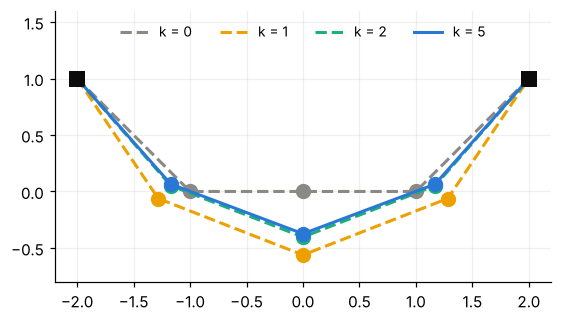

In [6]:
ch = rod_chain()                                             # цепь лекции 8: 3 груза, 4 стержня
ck = ch["kkt"]                                               # (grad f, J, H, g) от CasADi
lam0 = lam_ls(ck, ch["v0"], 4)                               # J^T lambda ≈ grad f по МНК
hist = newton_lagrange(ck, ch["v0"], lam0)
v_ip, lam_ip, st = solve_rod_chain(ch)                       # IPOPT, множители в нашем знаке
print("lambda(0) =", lam0.round(3))
print("|F| по итерациям:", np.array([h[2] for h in hist]).round(12))
print(f"наш метод: {len(hist) - 1} итераций, IPOPT: {st['iter_count']} итераций; в конспекте: 5 и 5")
print("lambda наш  :", hist[-1][1].round(4))
print("lambda IPOPT:", lam_ip.round(4), " разница", np.abs(hist[-1][1] - lam_ip).max().round(9))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for k, c in zip((0, 1, 2), (GRAY, YELLOW, AQUA)):
    draw_chain(ax, ch, hist[k][0], color=c, ls="--", label=f"k = {k}")
draw_chain(ax, ch, hist[-1][0], color=BLUE, label=f"k = {len(hist) - 1}")
ax.set_aspect("equal"); ax.legend(ncol=4, fontsize=9, loc="upper center"); ax.set_ylim(-0.8, 1.6); plt.show()

**Что видим.** Пять итераций — столько же, сколько у IPOPT. Множители $(-7.87,\ -5.58,\ -5.58,\ -7.87)$ совпадают с IPOPT до $10^{-6}$. После второй итерации форма цепи на глаз не меняется.

## (b) Матрица ККТ и шаг по частям (разделы 3–4)

**Что проверяем.** На цепи $K$ вырождена при $\lambda=0$ и в горизонтальном положении. На окружности и на цепи три способа §4 дают один шаг.

**Шаг 1. Что делает ячейка.** Собирает $K$ цепи на старте при $\lambda=0$ и при $\lambda^{(0)}$ по МНК, печатает ранг. Затем печатает ранг $J$ в горизонтальном положении $z=1$.

In [7]:
def kkt_matrix(kkt, x, lam):
    """Матрица ККТ [[H, -J^T], [J, 0]] в точке (x, lam)."""
    _, J, H, _ = kkt(x, lam)
    m = J.shape[0]
    return np.block([[H, -J.T], [J, np.zeros((m, m))]])

print("ранг K при lambda = 0:     ", np.linalg.matrix_rank(kkt_matrix(ck, ch["v0"], np.zeros(4))), "из 10")
print("ранг K при lambda по МНК:  ", np.linalg.matrix_rank(kkt_matrix(ck, ch["v0"], lam0)), "из 10")
print("собственные числа H при lambda по МНК:", np.linalg.eigvalsh(ck(ch["v0"], lam0)[2]).round(2))
v_hor = np.array([-1.0, 0.0, 1.0, 1.0, 1.0, 1.0])            # грузы на высоте z = 1
J_hor = ck(v_hor, np.zeros(4))[1]
print("горизонтальная цепь: ранг J =", np.linalg.matrix_rank(J_hor), "; J^T (1,1,1,1) =", J_hor.T @ np.ones(4))

ранг K при lambda = 0:      8 из 10
ранг K при lambda по МНК:   10 из 10
собственные числа H при lambda по МНК: [ 5.75  5.75 19.62 19.62 33.49 33.49]
горизонтальная цепь: ранг J = 3 ; J^T (1,1,1,1) = [0. 0. 0. 0. 0. 0.]


**Что видим.** При $\lambda=0$ ранг $K$ равен 8 из 10: $H=0$, и два касательных направления не определены. С множителями по МНК ранг 10, а собственные числа $H$ — от $5.7$ до $33.5$. В горизонтальном положении ранг $J$ равен 3, а сумма строк $J$ — ноль.

**Шаг 2. Что делает ячейка.** Функция `three_ways` находит шаг тремя способами §4: всей матрицей $K$, способом null-space и способом range-space. Запускаем её на окружности в $(1,1)$ и на цепи на старте.

In [8]:
def three_ways(kkt, x, lam):
    """Шаг (p, lambda+) тремя способами: вся K, null-space, range-space."""
    gf, J, H, g = kkt(x, lam)
    n, m = H.shape[0], J.shape[0]
    s = np.linalg.solve(kkt_matrix(kkt, x, lam), -np.concatenate([gf - J.T @ lam, g]))
    full = (s[:n], lam + s[n:])                                   # вся матрица (n + m) x (n + m)
    pN = -J.T @ np.linalg.solve(J @ J.T, g)                       # к ограничению: J pN = -g
    Z = null_space(J)                                             # базис касательного пространства
    u = np.linalg.solve(Z.T @ H @ Z, -Z.T @ (gf + H @ pN))        # система (n - m) x (n - m)
    p = pN + Z @ u
    null = (p, np.linalg.lstsq(J.T, H @ p + gf, rcond=None)[0])   # множители после шага
    lp = np.linalg.solve(J @ np.linalg.solve(H, J.T), J @ np.linalg.solve(H, gf) - g)   # система m x m
    rng = (np.linalg.solve(H, J.T @ lp - gf), lp)
    return full, null, rng, pN, Z @ u

for name, kkt, x, lam in (("окружность", circle_kkt(A_CIRCLE), np.array([1.0, 1.0]), np.zeros(1)),
                          ("цепь", ck, ch["v0"], lam0)):
    full, null, rng, pN, Zu = three_ways(kkt, x, lam)
    diff = max(np.abs(full[0] - null[0]).max(), np.abs(full[0] - rng[0]).max(), np.abs(full[1] - rng[1]).max())
    print(f"{name}: p = {full[0].round(4)}, lambda+ = {full[1].round(4)}, расхождение способов {diff:.0e}")
    if name == "окружность":
        print(f"   p_N = {pN.round(3)}, Zu = {Zu.round(3)}   (в конспекте: (-0.25, -0.25) и (0.5, -0.5))")

окружность: p = [ 0.25 -0.75], lambda+ = [-0.75], расхождение способов 1e-16
   p_N = [-0.25 -0.25], Zu = [ 0.5 -0.5]   (в конспекте: (-0.25, -0.25) и (0.5, -0.5))
цепь: p = [-0.2812  0.      0.2813 -0.0625 -0.5625 -0.0625], lambda+ = [-7.0509 -4.2919 -4.2919 -7.0509], расхождение способов 2e-15


**Что видим.** На окружности $p_N=(-0.25,\ -0.25)$ и $Zu=(0.5,\ -0.5)$, а $\lambda^+=-0.75$ — как в §4. На цепи три способа решают системы $10\times10$, $2\times2$ и $4\times4$. Шаг у всех один, расхождение — на уровне округления.

## (c) Обобщённый Гаусс–Ньютон (раздел 5)

**Что проверяем.** На окружности ошибка угла за шаг умножается на $\lambda^\ast=1-\lVert a\rVert$, а при $a=(2,1)$ метод качается.

**Что делает ячейка.** Запускает `ggn_circle` из $x^{(0)}=(0.6,\ 0.8)$ для трёх точек $a$. В матрице ККТ этого метода вместо $H=(1-\lambda)I$ стоит $I$. Печатает отношение соседних ошибок угла и число итераций до $10^{-8}$. Строит ошибку по итерациям.

|a| = 1.200: lambda* = -0.200, e_(k+1)/e_k = -0.200, итераций до 1e-8: 11
|a| = 1.500: lambda* = -0.500, e_(k+1)/e_k = -0.500, итераций до 1e-8: 25
|a| = 2.236: lambda* = -1.236, e_(k+1)/e_k = -1.002, итераций до 1e-8: не сходится


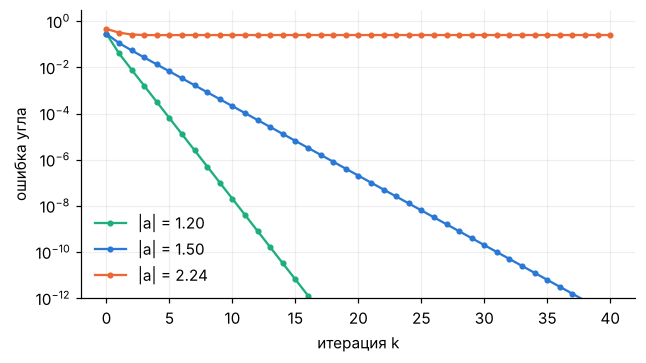

в конспекте: 11 и 25 итераций; при a = (2, 1) — не сходится


In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for a, c in ((np.array([0.96, 0.72]), AQUA), (np.array([1.2, 0.9]), BLUE), (A_CIRCLE, ORANGE)):
    e = angle_err(ggn_circle(a, [0.6, 0.8], 40), a)          # ошибка угла по итерациям
    lam_star = 1 - np.linalg.norm(a)                          # множитель ближней точки
    hit = np.nonzero(np.abs(e) <= 1e-8)[0]
    its = hit[0] if len(hit) else "не сходится"
    print(f"|a| = {np.linalg.norm(a):.3f}: lambda* = {lam_star:+.3f}, e_(k+1)/e_k = {e[6] / e[5]:+.3f}, итераций до 1e-8: {its}")
    ax.semilogy(np.abs(e) + 1e-17, "o-", ms=3, color=c, label=f"|a| = {np.linalg.norm(a):.2f}")
ax.set_xlabel("итерация k"); ax.set_ylabel("ошибка угла"); ax.set_ylim(1e-12, 3); ax.legend(); plt.show()
print("в конспекте: 11 и 25 итераций; при a = (2, 1) — не сходится")

**Что видим.** При $\lVert a\rVert=1.2$ и $1.5$ отношение ошибок — $-0.2$ и $-0.5$, ровно $\lambda^\ast$. При $a=(2,1)$ ошибка угла застревает около $0.25$: метод качается между двумя точками.

## (e) Подробности

**Старт из арки. Что делает ячейка.** Запускает метод из арки $(-1,\ 2)$, $(0,\ 2.5)$, $(1,\ 2)$ и печатает множители и энергию ответа. Затем — редуцированный гессиан в обоих ответах.

In [10]:
v_arch = np.array([-1.0, 0.0, 1.0, 2.0, 2.5, 2.0])         # y1, y2, y3, z1, z2, z3
ha = newton_lagrange(ck, v_arch, lam_ls(ck, v_arch, 4))
for name, (x, lam) in (("арка", ha[-1][:2]), ("висящая цепь", hist[-1][:2])):
    _, J, H, _ = ck(x, lam)
    Z = null_space(J)                                         # базис касательного пространства, 6 x 2
    print(f"{name}: lambda = {lam.round(2)}, f = {ch['w'] * x[3:].sum():.2f}, Z^T H Z: собственные числа {np.linalg.eigvalsh(Z.T @ H @ Z).round(1)}")
print(f"арка: итераций {len(ha) - 1}; в конспекте: 4 итерации, f = 61.25")

арка: lambda = [7.87 5.58 5.58 7.87], f = 61.25, Z^T H Z: собственные числа [-35.2 -19. ]
висящая цепь: lambda = [-7.87 -5.58 -5.58 -7.87], f = -2.39, Z^T H Z: собственные числа [19.  35.2]
арка: итераций 4; в конспекте: 4 итерации, f = 61.25


**Что видим.** В арке все $\lambda_j>0$, а редуцированный гессиан отрицательно определён: $-35.2$ и $-19.0$. Это максимум, и матрица ККТ там тоже невырождена. В висящей цепи те же числа со знаком плюс.

**Выбор $\lambda^{(0)}$. Что делает ячейка.** Запускает метод на цепи из прямой $z=0$ с разными стартовыми множителями.

In [11]:
for name, l0 in (("по МНК", lam0), ("все -1", -np.ones(4)), ("все -20", -20 * np.ones(4))):
    h = newton_lagrange(ck, ch["v0"], l0)
    ok = np.allclose(h[-1][0], hist[-1][0], atol=1e-6)
    print(f"lambda(0) {name:7s}: {len(h) - 1:2d} итераций, max |F| по пути {max(t[2] for t in h):8.2f}, тот же ответ: {ok}")

lambda(0) по МНК :  5 итераций, max |F| по пути     9.86, тот же ответ: True
lambda(0) все -1 :  7 итераций, max |F| по пути    69.44, тот же ответ: True
lambda(0) все -20:  8 итераций, max |F| по пути    43.82, тот же ответ: True


**Что видим.** С множителями по МНК — 5 итераций и невязка только убывает. С плохими множителями первый шаг уводит далеко, и итераций больше. Множители по МНК — дешёвый и надёжный старт.

**Лог IPOPT рядом с нашей невязкой. Что делает ячейка.** Берёт из `st["iterations"]` колонки `inf_pr` и `inf_du` и сравнивает с половинами нашей невязки: $\lVert g\rVert_\infty$ и $\lVert\nabla_xL\rVert_\infty$.

In [12]:
ours = []
for x, lam, _ in hist:
    gf, J, H, g = ck(x, lam)
    ours.append((np.abs(g).max(), np.abs(gf - J.T @ lam).max()))   # половины F в норме max
it = st["iterations"]
print(" k   наш |g|     IPOPT inf_pr   наш |grad L|  IPOPT inf_du")
for k in range(len(ours)):
    print(f"{k:2d}  {ours[k][0]:10.2e}  {it['inf_pr'][k]:12.2e}  {ours[k][1]:12.2e}  {it['inf_du'][k]:12.2e}")
print("длины шагов IPOPT alpha_pr:", it["alpha_pr"][1:])

 k   наш |g|     IPOPT inf_pr   наш |grad L|  IPOPT inf_du
 0    5.62e-01      5.62e-01      9.81e+00      9.81e+00
 1    3.29e-01      3.29e-01      1.23e+00      1.23e+00
 2    2.53e-02      2.53e-02      3.61e-01      3.61e-01
 3    2.53e-04      2.53e-04      1.81e-02      1.81e-02
 4    1.55e-07      1.55e-07      7.96e-06      7.96e-06
 5    2.61e-13      2.61e-13      3.54e-12      3.54e-12
длины шагов IPOPT alpha_pr: [1.0, 1.0, 1.0, 1.0, 1.0]


**Что видим.** Числа совпадают до ошибок округления: на этой задаче IPOPT делает те же шаги, что наш метод. Стартовые множители он тоже берёт по МНК, а линейный поиск каждый раз принимает полный шаг (`alpha_pr` $=1$).

## Шпаргалка

| Что | Формула | Где в конспекте |
|---|---|---|
| система | $F=(\nabla f-J^\top\lambda,\ g)=0$ | §2.2 |
| матрица ККТ | $K=\begin{pmatrix}H&-J^\top\\J&0\end{pmatrix}$ | §2.2 |
| когда $K$ невырождена | LICQ и $Z^\top HZ\succ0$ | §3 |
| null-space | $p=p_N+Zu$, система $(n-m)\times(n-m)$ | §4.1 |
| range-space | $JH^{-1}J^\top\lambda^+=JH^{-1}\nabla f-g$ | §4.2 |
| обобщённый Гаусс–Ньютон | $H\to J_r^\top J_r$ | §5 |

**Три вещи, которые легко перепутать.**

1. Метод Ньютона–Лагранжа ищет решение системы, а не минимум. Из арки он приходит в максимум.
2. Промежуточные точки нарушают ограничения: $g=0$ выполняется только в пределе.
3. У обобщённого Гаусса–Ньютона нет $\lambda$ в матрице, но множитель ошибки равен $\lambda^\ast$. Малые невязки — быстрая сходимость.